# Задача 9. Markov Chain Monte-Carlo (PyMC)

В этой задаче мы реализуем модель генерации и детектирования света из Задач 1-3 с помощью вероятностного программирования (PyMC).
Вместо того чтобы циклом перебирать миллионы фотонов, мы опишем статистический граф:
1. Рождение фотонов (Пуассон).
2. Попадание в ФЭУ (биномиальное/пуассоновское распределение).
3. Суммарный заряд.

Затем мы сэмплируем из этой модели с помощью `pm.sample_prior_predictive` (так как наблюдаемых данных у нас нет, мы просто симулируем отклик) и сравниваем с результатом из Задачи 4.

In [5]:
# Установка библиотек (в Colab PyMC может отсутствовать по умолчанию)
!pip install pymc arviz -q

import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt

In [7]:
# Параметры детектора и источника
E_val = 1.0
Y_val = 10000.0
a_val = 0.5
R_val = 2.0
r_val = 0.1
N_pmts = 40

# Вероятность попасть в один ФЭУ с учетом квантовой эффективности
p_geom = (r_val**2) / (4 * R_val**2)
p_hit = a_val * p_geom

with pm.Model() as detector_model:
    # Константы (данные) - используем pm.Data вместо pm.ConstantData
    E = pm.Data('E', E_val)
    Y = pm.Data('Y', Y_val)

    # 1. Рождение фотонов (среднее = E * Y)
    N_photons = pm.Poisson('N_photons', mu=E * Y)

    # 2. Рождение фотоэлектронов в каждом из 40 ФЭУ
    # Среднее число ФЭ на один ФЭУ = N_photons * p_hit
    pes_per_pmt = pm.Poisson('pes_per_pmt', mu=N_photons * p_hit, shape=(N_pmts,))

    # 3. Суммарный заряд (сумма по всем ФЭУ)
    total_charge = pm.Deterministic('total_charge', pt.sum(pes_per_pmt))

# Выводим граф модели (опционально, полезно для понимания)
# pm.model_to_graphviz(detector_model)

Средний заряд (PyMC): 125.05
Стандартное отклонение (PyMC): 11.29


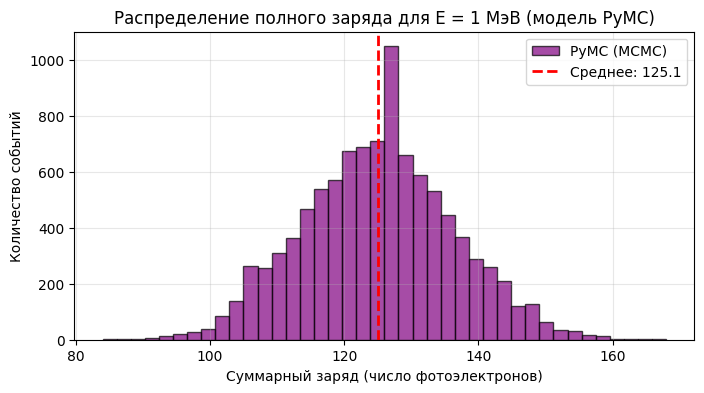

In [8]:
with detector_model:
    # Генерируем 10000 событий
    prior_pred = pm.sample_prior_predictive(samples=10000, model=detector_model)

# Достаем семплы полного заряда
charges_pymc = prior_pred.prior['total_charge'].values.flatten()

# Выводим статистику
print(f"Средний заряд (PyMC): {np.mean(charges_pymc):.2f}")
print(f"Стандартное отклонение (PyMC): {np.std(charges_pymc):.2f}")

# Строим гистограмму
plt.figure(figsize=(8, 4))
plt.hist(charges_pymc, bins=40, alpha=0.7, color='purple', edgecolor='black', label='PyMC (MCMC)')
plt.axvline(np.mean(charges_pymc), color='red', linestyle='dashed', linewidth=2, label=f'Среднее: {np.mean(charges_pymc):.1f}')
plt.title('Распределение полного заряда для E = 1 МэВ (модель PyMC)')
plt.xlabel('Суммарный заряд (число фотоэлектронов)')
plt.ylabel('Количество событий')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

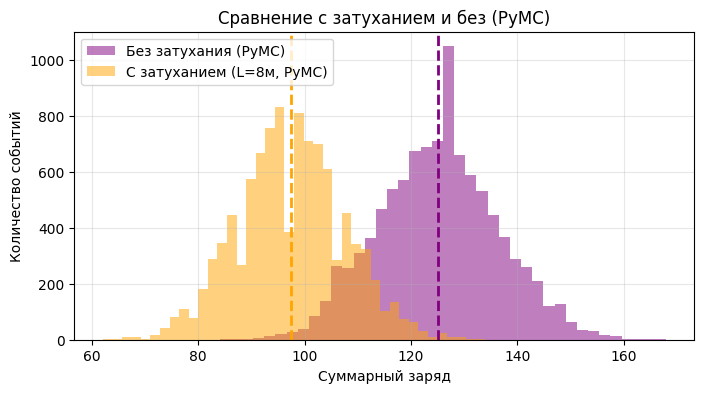

Средний заряд (Без затухания): 125.05
Средний заряд (С затуханием): 97.43
Отношение: 0.7791 (Теория: 0.7788)


In [10]:
L_attenuation = 8.0
survival_prob = np.exp(-R_val / L_attenuation)
p_hit_attenuated = p_hit * survival_prob

with pm.Model() as detector_model_attn:
    E = pm.Data('E', E_val)
    Y = pm.Data('Y', Y_val)

    N_photons = pm.Poisson('N_photons', mu=E * Y)

    # Используем новую вероятность с учетом поглощения
    pes_per_pmt = pm.Poisson('pes_per_pmt', mu=N_photons * p_hit_attenuated, shape=(N_pmts,))
    total_charge = pm.Deterministic('total_charge', pt.sum(pes_per_pmt))

with detector_model_attn:
    prior_pred_attn = pm.sample_prior_predictive(samples=10000, model=detector_model_attn)

charges_attn = prior_pred_attn.prior['total_charge'].values.flatten()

plt.figure(figsize=(8, 4))
plt.hist(charges_pymc, bins=40, alpha=0.5, color='purple', label='Без затухания (PyMC)')
plt.hist(charges_attn, bins=40, alpha=0.5, color='orange', label='С затуханием (L=8м, PyMC)')
plt.axvline(np.mean(charges_pymc), color='purple', linestyle='dashed', linewidth=2)
plt.axvline(np.mean(charges_attn), color='orange', linestyle='dashed', linewidth=2)
plt.title('Сравнение с затуханием и без (PyMC)')
plt.xlabel('Суммарный заряд')
plt.ylabel('Количество событий')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Средний заряд (Без затухания): {np.mean(charges_pymc):.2f}")
print(f"Средний заряд (С затуханием): {np.mean(charges_attn):.2f}")
print(f"Отношение: {np.mean(charges_attn)/np.mean(charges_pymc):.4f} (Теория: {survival_prob:.4f})")